# Tutorial 4 · Two coupled Xmons: the design loop with feedback

Tutorial 0 built one qubit and its readout. This one builds **two Xmons side by side**, coupled through their facing
cross arms, each read out by its own λ/4 hanger on one shared feedline, and runs the whole loop **as a loop**: the
design is a function of a few knobs, the LOM and the FEM measure it, and a feedback step turns the differences into
new knobs until the chip lands on its targets. At the end you give a new qubit frequency and the notebook redesigns,
re-simulates and writes the fab layout.

```
targets ─► LOM-first synthesis ─► design(knobs) ─► build ─► DRC ─► LOM (QuCat + QuTiP) ─► LOM loop
   ▲                                                                                      │
   │        feedback: FEM − LOM correction → new knobs ◄── bring back ◄── FEM (Q3D + eigenmode/EPR [+ driven])
   └──────────────────────────────── rebuild → re-simulate → … → fab export (cheese, rounding)
```

| target | symbol | knob that moves it | update rule |
|---|---|---|---|
| Q1, Q2 frequency | f_q1, f_q2 | cross length (and, out of range, the junction within the PDK R_n window) | L·C ∝ 1/f² |
| R1, R2 frequency | f_r1, f_r2 | the λ/4 meander length | λ/4 ∝ 1/f |
| qubit–qubit coupling | g = J₁₂ | the ground strip between the facing arm tips | J ∝ C_c; C_c = a power law of the tip gap, anchored on the last C-matrix |

**How to run.** As tutorial 0: live in KLayout by default, headless with `QCC_LIVE=0`. With `RUN_FEM = False`
(default) every FEM cell reads the results kept in `examples/tutorials/fem/`; without kept results it says so and
the loop runs on the LOM alone. Runtime ≈ 4 min (LOM loops of ≈ 1 min each); with `RUN_FEM = True` add one Q3D
(≈ 3–5 min) and one eigenmode/EPR (≈ 15–25 min) per FEM iteration on this workstation (the driven S21 job is
exported too and solved only when asked for, ≈ 40 min).

**`KLAYOUT_GUI`** (next to `LIVE`): `True` opens the KLayout window when it is not running (≈ 15–20 s the first time, with the layout and the Quantcore plugin), reopens it if you closed it, and brings it to the front on the first build; `False` only redraws a KLayout you already have open (klive).

**Dashboard** (`track.start("t04")` in the setup cell): every build, DRC, LOM run, FEM job (with its pass / Δ / mesh while AEDT runs) and feedback step is recorded into `build/t04/state.json`; `scripts\dashboard.cmd` in a terminal shows it live at http://127.0.0.1:8765/ (`track.stop()` switches the recording off).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "examples" / "tutorials"))
import _tut as T                                  # tutorial helpers (tables, snapshots, FEM round trip)
T.setup("t04")                                    # working directory = repo root; pictures → examples/tutorials/img/
import _common as C                               # design-notebook helpers (netlist / mode tables, …)
from quantcore_circuits.designer import Designer
from quantcore_circuits.pdk import get_pdk

KLAYOUT_GUI = True                                # True: open / raise the KLayout window; False: redraw an open one only
LIVE = T.live_mode(gui=KLAYOUT_GUI)               # True: KLayout via KLive; False: headless (QCC_LIVE=0)
from quantcore_circuits import track
TRACKING = track.start("t04")                     # dashboard (scripts\dashboard.cmd) follows build/t04

Headless (QCC_LIVE=0): each build writes build/<name>.oas; pictures are headless KLayout snapshots.


### The FEM part in two stages, and its switches

Every tutorial runs its FEM part in two stages: (1) a **subset check**, FEM only — the convergence, the raw C-matrix,
eigenmodes and S21 notches, the FEM-filled capacitances next to their estimates; if they are sane and converged, go
on — and (2) **the whole LOM**: fill the subset values into the whole netlist (the rest keep their estimates), simulate the LOM, compare LOM and FEM, feed back, rebuild.
No LOM is simulated on a subset and nothing is fed back from it.

**`SIM_SUBSET`** says which part of the chip is rendered and simulated: `(qubit, readout)` pairs — here both,
`[("Q1", "R1"), ("Q2", "R2")]`, i.e. the chip minus its pads (`Designer.sim_subset` makes the `PAIR` Q3D group and the
`ALL` eigenmode / driven group from it; the box cuts the feedline into two 50 Ω ports; Q1 and Q2 share a box because
their facing arms are a declared coupling) — so stage 2 uses the stage-1 jobs of each revision (no second solve).
`FEM_WHOLE = True` (opt-in) takes the chip with its pads (the built-in group `chip`). The feedback loop corrects both qubits, so it
needs both pairs (or `"whole"`). `RESOLVE` re-solves jobs whose kept results match (after a library fix, say).

In [3]:
SIM_SUBSET = [("Q1", "R1"), ("Q2", "R2")]   # the pairs to render and simulate, or "whole" (the chip with its pads)
FEM_WHOLE = False                # True (opt-in, slower): the whole chip with its pads instead of the subset
if FEM_WHOLE:
    SIM_SUBSET = "whole"
RUN_FEM = False                  # True (or a set of analyses, e.g. {"q3d_cmatrix", "eigenmode_epr"}): solve in AEDT
RESOLVE = False                  # True (or a set of analyses): re-solve even when the kept results match
FEM_FAST = True                  # True: fast test settings (few passes, values not converged); False: converged settings
AEDT_MODE = "batch"            # "batch" (no window) | "gui" (a new AEDT window) | "attach" (yours)

## 1 · Targets and the PDK rules they live in

Five targets: two qubit frequencies 300 MHz apart (detuned, so they do not hybridise), two readout frequencies 300 MHz
apart, and the qubit–qubit exchange coupling g = J₁₂. The tolerances are what the loop stops on.

The PDK fixes the rest (tutorial 0 has the full table): sapphire 650 µm, the 10/6 µm CPW, pads 100 µm from the die
edge, the trilayer junction with **R_n 40–50 kΩ** (so L_J ≈ 6.0–7.5 nH, drawn on a 0.01 µm finger grid: L_J comes in
≈ 2 % steps), the cheese band and the corner rounding of the fab export.

In [4]:
from quantcore_circuits.circuit.bridges import lj_from_rn

pdk = get_pdk()
TARGETS = {"Q1.f_q_GHz": 5.35, "Q2.f_q_GHz": 5.65, "R1.f_GHz": 7.00, "R2.f_GHz": 7.30, "g12_MHz": 10.0}
TOL = {"Q1.f_q_GHz": 0.005, "Q2.f_q_GHz": 0.005, "R1.f_GHz": 0.005, "R2.f_GHz": 0.005, "g12_MHz": 0.3}
UNIT = {"Q1.f_q_GHz": "GHz", "Q2.f_q_GHz": "GHz", "R1.f_GHz": "GHz", "R2.f_GHz": "GHz", "g12_MHz": "MHz"}
LJ_MIN, LJ_MAX = (lj_from_rn(r * 1e3) for r in pdk.junction.rn_target_kohm)   # the PDK junction window (nH)
CROSS_MIN, CROSS_MAX, STRIP_MIN, STRIP_MAX = 300.0, 600.0, 5.0, 120.0           # knob ranges (µm)
T.md("| target | value | tolerance |\n|---|---|---|\n" + "\n".join(
    f"| `{k}` | {v:g} {UNIT[k]} | ± {TOL[k]:g} |" for k, v in TARGETS.items()))
print(f"PDK {pdk.name}: pads {pdk.frame.pad_edge:g} µm from the edge; junction R_n {pdk.junction.rn_target_kohm} kΩ "
      f"→ L_J {LJ_MIN:.2f}–{LJ_MAX:.2f} nH")

| target | value | tolerance |
|---|---|---|
| `Q1.f_q_GHz` | 5.35 GHz | ± 0.005 |
| `Q2.f_q_GHz` | 5.65 GHz | ± 0.005 |
| `R1.f_GHz` | 7 GHz | ± 0.005 |
| `R2.f_GHz` | 7.3 GHz | ± 0.005 |
| `g12_MHz` | 10 MHz | ± 0.3 |

PDK quantcore_nb_sapphire_v1: pads 100 µm from the edge; junction R_n (40.0, 50.0) kΩ → L_J 5.99–7.48 nH


## 2 · The design as a function of its knobs

`design(knobs)` draws the whole chip from ten numbers, so every revision of the loop is the same code with other
knobs:

- two `BondPad`s with `edge="auto"` (the 100 µm pad rule) and the feedline `FL` between them (as tutorial 0);
- `Q1` at `x1` and `Q2` to its right: Xmons with a north claw `claw_n`, a trilayer junction sized for `lj1` / `lj2`
  (`trilayer_junction`), their cross lengths `cross1` / `cross2`. Q2's centre follows from the cross lengths and the
  ground strip, so the arm tips always face each other across 2 × 25 µm of gap plus the **strip**;
- `R1` / `R2`: λ/4 meanders (`len1` / `len2`) from each claw to a hanger centred above its qubit (`near=`), coupler
  `cpl1` / `cpl2` µm long, shorted at the far end;
- the arm-to-arm capacitance `C_Q1Q2` is declared with `d.couple` (no route carries it). Its value comes from the
  **coupling model** `CC`: a power law C_c = C₀ (gap₀ / gap)^p of the tip gap — the library's own surrogate element
  (`codesign.ElementModel`, on the inverse gap) — anchored at first on the screened coplanar-strip estimate and later
  on each C-matrix the FEM returns (two FEM points fit p; until then p = 1.5 is the prior).

In [5]:
from quantcore_circuits.codesign import ElementModel
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.lom import estimates as est

GAP, ARM, Y_Q, Y_FL = 25.0, 25.0, 2838.0, 4488.0  # Xmon gap and arm width, qubit row, feedline row (µm):
                                                  # the rows put the content in the die centre (PDK rule)
TIP0 = 2 * GAP + 10.0                             # tip gap of the anchor point (a 10 µm strip)
CC = ElementModel("C_Q1Q2", "1/tip_gap", 1 / TIP0,
                  est.coplanar_coupling(ARM, 225, 225, TIP0, est.substrate_eps(pdk.name), 0.3), p=1.5, prior_p=1.5)


def c_arms(strip):
    """The coupling model: C_c (fF) of the facing arm tips across 2·GAP + strip."""
    return CC.predict(1 / (2 * GAP + strip))


def strip_for(c_fF):
    """Inverse of the coupling model: the ground strip (µm) that gives C_c = c_fF."""
    return 1 / CC.invert(c_fF) - 2 * GAP


def design(knobs, name="t04_two_qubit", live=False):
    """The two-qubit chip for ``knobs`` (see the table above)."""
    d = Designer(name, box=(0, 0, 7500, 7500), chip={"name_chip": "QS2"}, live=live, verbose=False)
    with d.batch():                               # one rebuild (live: one redraw) for the whole chip
        pw = d.add("PAD_W", "BondPad", at=(1125, Y_FL), rot=270, edge="auto")
        pe = d.add("PAD_E", "BondPad", at=(6375, Y_FL), rot=90, edge="auto")
        fl = d.route("FL", pw.a, pe.a)
        x = {"1": knobs["x1"]}
        x["2"] = x["1"] + (knobs["cross1"] + knobs["cross2"]) / 2 + 2 * GAP + knobs["strip"]
        for i in "12":
            params, junction = trilayer_junction("Xmon", lj_nH=knobs[f"lj{i}"])
            q = d.add(f"Q{i}", "Xmon", at=(x[i], Y_Q), cross_length=knobs[f"cross{i}"], arm_width=ARM, gap=GAP,
                      claws=["n"], junction=junction, **params)
            d.route(f"R{i}", q.claw_n, fl.hanger(near=(x[i], Y_FL), length=knobs[f"cpl{i}"], side="right"),
                    meander=knobs[f"len{i}"], r=50)
    d.couple("C_Q1Q2", "Q1", "Q2", C_fF=round(c_arms(knobs["strip"]), 4),
             note=f"facing arm tips across {2 * GAP + knobs['strip']:.1f} µm (coupling model CC)")
    d.targets(Q1={"f_q_GHz": TARGETS["Q1.f_q_GHz"]}, Q2={"f_q_GHz": TARGETS["Q2.f_q_GHz"]},
              R1={"f_GHz": TARGETS["R1.f_GHz"]}, R2={"f_GHz": TARGETS["R2.f_GHz"]})
    return d

## 3 · LOM-first synthesis: the first knobs from the targets

No layout is guessed by hand:

- **readouts** — the bare λ/4 length for each f_r on the PDK CPW (kinetic inductance included). The claw loads the
  open end, so these land low; the LOM loop of section 5 shortens them;
- **junctions** — a first draft at cross 450 µm gives each island's C_Σ (LOM estimate); `size_junction(f_q, C_Σ)`
  gives the L_J for the target and the R_n it implies (inside 40–50 kΩ here). From then on the cross length tunes
  f_q continuously, because the drawn L_J only comes in ≈ 2 % steps;
- **coupling** — J ≈ C_c √(f₁f₂) / (2 √(C_Σ1 C_Σ2)) gives the C_c for the J target, and the coupling model the strip.

In [6]:
from quantcore_circuits.analysis.synthesis import quarter_wave_length_um
from quantcore_circuits.circuit.bridges import size_junction

knobs = {"x1": 3100.0, "cross1": 450.0, "cross2": 450.0, "lj1": 6.73, "lj2": 6.73, "strip": 10.0,
         "cpl1": 300.0, "cpl2": 300.0,
         "len1": quarter_wave_length_um(TARGETS["R1.f_GHz"], pdk.cpw_a, pdk.cpw_b),
         "len2": quarter_wave_length_um(TARGETS["R2.f_GHz"], pdk.cpw_a, pdk.cpw_b)}
draft = design(knobs, "t04_draft").lom().model
c_sigma, sizing = {}, []
for i in "12":
    c_sigma[i] = sum(b.value["estimate"] for n, b in draft.branches.items() if n in (f"C_Q{i}", f"Cg_Q{i}_claw_n"))
    s = size_junction(TARGETS[f"Q{i}.f_q_GHz"], c_sigma[i], c_includes_junction=False)
    knobs[f"lj{i}"] = round(s.lj_nH, 3)
    sizing.append(f"| Q{i} | {c_sigma[i]:.1f} | {s.lj_nH:.3f} | {s.rn_kohm:.1f} | {s.rn_in_window} |")
cj = 15.0                                         # ≈ the trilayer junction's C_J (fF)
c_need = (2 * TARGETS["g12_MHz"] * 1e-3 * math.sqrt((c_sigma["1"] + cj) * (c_sigma["2"] + cj))
          / math.sqrt(TARGETS["Q1.f_q_GHz"] * TARGETS["Q2.f_q_GHz"]))
knobs["strip"] = round(min(max(strip_for(c_need), STRIP_MIN), STRIP_MAX), 2)
T.md("| qubit | C_Σ estimate (fF) | L_J for f_q (nH) | R_n (kΩ) | in the PDK window |\n|---|---|---|---|---|\n"
     + "\n".join(sizing))
print(f"C_c for J = {TARGETS['g12_MHz']:g} MHz: {c_need:.3f} fF → strip {knobs['strip']:.1f} µm "
      f"(tip gap {2 * GAP + knobs['strip']:.1f} µm)")
T.md("| knob | value |\n|---|---|\n" + "\n".join(f"| `{k}` | {v:.4g} |" for k, v in knobs.items()))

| qubit | C_Σ estimate (fF) | L_J for f_q (nH) | R_n (kΩ) | in the PDK window |
|---|---|---|---|---|
| Q1 | 99.2 | 7.354 | 49.1 | True |
| Q2 | 99.2 | 6.520 | 43.6 | True |

C_c for J = 10 MHz: 0.416 fF → strip 45.7 µm (tip gap 95.7 µm)


| knob | value |
|---|---|
| `x1` | 3100 |
| `cross1` | 450 |
| `cross2` | 450 |
| `lj1` | 7.354 |
| `lj2` | 6.52 |
| `strip` | 45.74 |
| `cpl1` | 300 |
| `cpl2` | 300 |
| `len1` | 4501 |
| `len2` | 4316 |

## 4 · Build, DRC, netlist

One build of the synthesised knobs (live: drawn in KLayout). The DRC checks connectivity, overlaps, route
clearances, the die frame and the PDK margins; the netlist is the layout's connectivity: pads → 50 Ω ports on `FL`;
each qubit → island (C and the trilayer JJ to ground, C_g to its claw); each readout → a λ/4 `TLres` from the claw to
ground plus a `HANGER` κ element to `FL`; and `C_Q1Q2` between the two islands.

**DRC clean** — 0 errors, 0 warnings, 0 PDK design warnings

| severity | rule | count | example |
|---|---|---|---|
| – | – | 0 | – |

| pad | asked at (x, y) µm | outer etch edge → die edge (µm) |
|---|---|---|
| `PAD_W` | (1125, 4488) | 100.0 |
| `PAD_E` | (6375, 4488) | 100.0 |

**6 nodes · 15 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `FL` | `FL`, `PAD_W.pad`, `PAD_E.pad` |
| `Q1` | `Q1.island` |
| `Q1.claw_n` | `Q1.claw_n` |
| `Q2` | `Q2.island` |
| `Q2.claw_n` | `Q2.claw_n` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_PAD_W` | R | `FL` – `gnd` | 50 Ω |
| `Port_PAD_E` | R | `FL` – `gnd` | 50 Ω |
| `C_Q1` | C | `Q1` – `gnd` | 96.1 fF |
| `J_Q1` | JJ | `Q1` – `gnd` | Lj 7.32 nH, Cj 13.8 fF |
| `Cg_Q1_claw_n` | C | `Q1` – `Q1.claw_n` | 3.17 fF |
| `Cc_Q1_claw_n` | C | `Q1.claw_n` – `gnd` | 76.4 fF |
| `C_Q2` | C | `Q2` – `gnd` | 96.1 fF |
| `J_Q2` | JJ | `Q2` – `gnd` | Lj 6.48 nH, Cj 15.6 fF |
| `Cg_Q2_claw_n` | C | `Q2` – `Q2.claw_n` | 3.17 fF |
| `Cc_Q2_claw_n` | C | `Q2.claw_n` – `gnd` | 76.4 fF |
| `C_C_Q1Q2` | C | `Q1` – `Q2` | 0.416 fF |
| `R1` | TLres | `Q1.claw_n` – `gnd` | lambda/4, 4501 µm, 7.000 GHz |
| `K_R1` | HANGER | `Q1.claw_n` – `FL` | κ 0.214 MHz (L 300 µm) |
| `R2` | TLres | `Q2.claw_n` – `gnd` | lambda/4, 4316 µm, 7.300 GHz |
| `K_R2` | HANGER | `Q2.claw_n` – `FL` | κ 0.243 MHz (L 300 µm) |

**Unconnected ports:** none

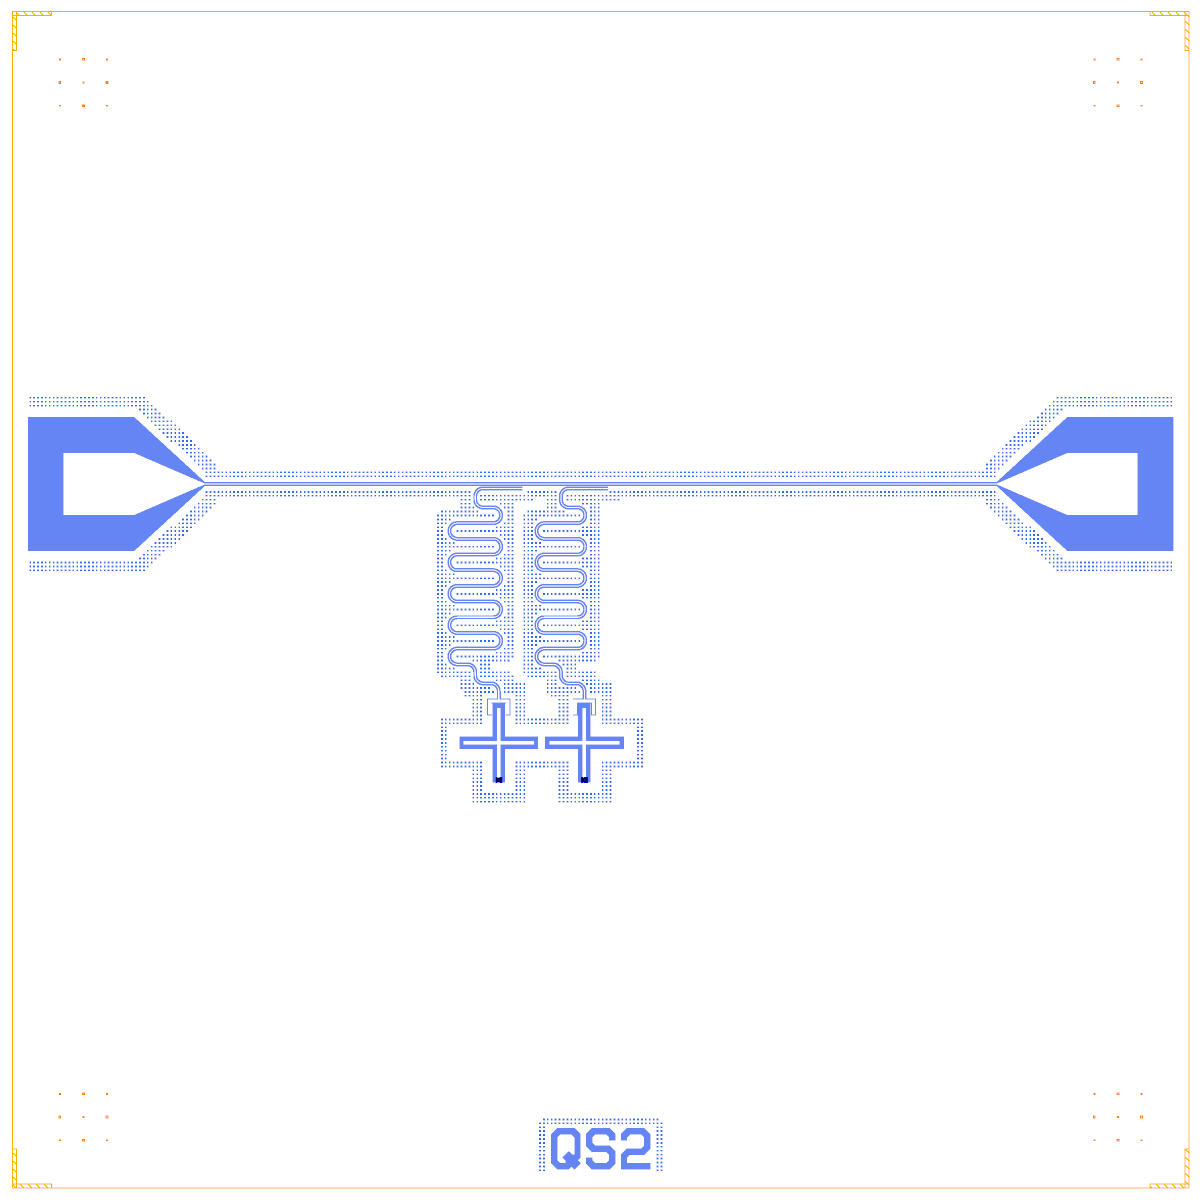

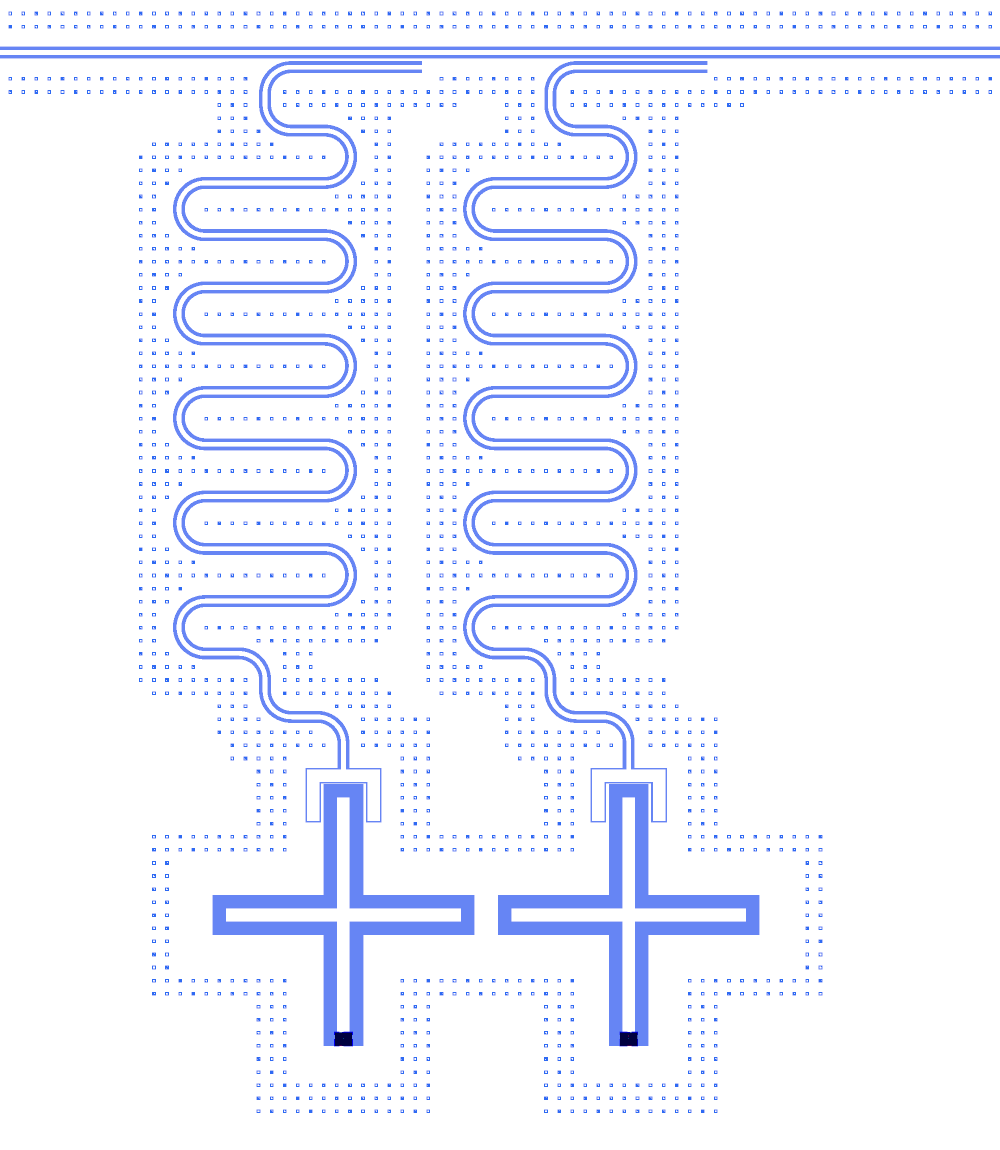

WindowsPath('examples/tutorials/img/t04_pair.png')

In [7]:
d = design(knobs, live=LIVE)
rep = T.drc(d)
T.md(T.drc_md(rep))
T.md(T.pad_edges_md(d))
C.show_netlist(d.lom())
T.snap(d, "chip", size=(1200, 1200), width=480)
PAIR_BOX = (2450, Y_Q - 450, 4350, Y_FL + 100)   # the two qubits, their readouts and the feedline above them
T.snap(d, "pair", box=PAIR_BOX, size=(1000, 1150), width=480)

## 5 · LOM simulation and the LOM loop

`lom_values(d)` measures the five targets on the layout's LOM: QuCat normal modes of the whole circuit and QuTiP on
the four leading modes (≤ 1200 states) give f_q1, f_q2, f_r1, f_r2 (dressed); J is the splitting of the avoided crossing of the two
qubits (`T.exchange_on`: Q2's L_J is swept through Q1's frequency in the two-qubit sub-circuit).

`update(knobs, values, targets)` applies the three rules of the table at the top, and `lom_loop` repeats
build → LOM → update until every value is inside its tolerance. Each step is a full rebuild (≈ 10 s here, most of it
QuTiP).

In [8]:
from quantcore_circuits.circuit.fill import fill
from quantcore_circuits.lom.simulate import simulate

F_KEYS = ["Q1.f_q_GHz", "Q2.f_q_GHz", "R1.f_GHz", "R2.f_GHz"]


def lom_values(d):
    """The five target values of ``d`` on its LOM (component estimates), plus α, χ, κ for the tables."""
    res = simulate(fill(d.lom().model, d.design), max_modes=4, max_dim=1200)   # 4 modes, ≤ 1200 states
    v = dict(res.params)
    v["g12_MHz"] = T.exchange_on(d.lom(select=["Q1", "Q2"]).model, d.design, "Q1", "Q2", max_modes=2)["J_MHz"]
    return v


def update(knobs, v, t):
    """One feedback step on the knobs: λ/4 ∝ 1/f; L·C ∝ 1/f² (cross length first, the junction when the cross
    leaves its range); J ∝ C_c through the coupling model."""
    k = dict(knobs)
    for i in "12":
        k[f"len{i}"] = knobs[f"len{i}"] * v[f"R{i}.f_GHz"] / t[f"R{i}.f_GHz"]
        s = (v[f"Q{i}.f_q_GHz"] / t[f"Q{i}.f_q_GHz"]) ** 2
        if CROSS_MIN <= knobs[f"cross{i}"] * s <= CROSS_MAX:
            k[f"cross{i}"] = knobs[f"cross{i}"] * s
        else:                                     # PDK: move the junction (in its R_n window), keep the cross
            k[f"lj{i}"] = min(max(knobs[f"lj{i}"] * s, LJ_MIN), LJ_MAX)
    c_new = c_arms(knobs["strip"]) * t["g12_MHz"] / v["g12_MHz"]
    k["strip"] = min(max(strip_for(c_new), STRIP_MIN), STRIP_MAX)
    return k


def converged(v, t):
    return all(abs(v[key] - t[key]) <= TOL[key] for key in t)


def lom_loop(knobs, t, name, max_iter=8, verbose=True):
    """build → LOM → update until the LOM values are within TOL of ``t``. Returns (knobs, values, rows)."""
    rows = []
    for it in range(max_iter):
        v = lom_values(design(knobs, name))
        rows.append((it, dict(knobs), {k: v[k] for k in t}))
        if verbose:
            print(f"  step {it}: " + ", ".join(f"{k} {v[k]:.4f}" for k in t))
        if converged(v, t):
            break
        knobs = update(knobs, v, t)
    return knobs, v, rows


def values_md(cols: dict, t=TARGETS) -> str:
    """Columns of target values side by side with the targets."""
    out = ["| quantity | target | " + " | ".join(cols) + " |", "|---|---|" + "---|" * len(cols)]
    for k in t:
        out.append(f"| `{k}` | {t[k]:g} | " + " | ".join("–" if (c or {}).get(k) is None else f"{c[k]:.4f}"
                                                         for c in cols.values()) + " |")
    return "\n".join(out)


v_synth = lom_values(d)
T.md(values_md({"LOM (synthesis)": v_synth}))
print("LOM loop:")
knobs0, v0, rows0 = lom_loop(knobs, TARGETS, "t04_two_qubit")
T.md(T.before_after_md({k: knobs[k] for k in knobs0}, knobs0))

| quantity | target | LOM (synthesis) |
|---|---|---|
| `Q1.f_q_GHz` | 5.35 | 5.3445 |
| `Q2.f_q_GHz` | 5.65 | 5.6508 |
| `R1.f_GHz` | 7 | 6.2513 |
| `R2.f_GHz` | 7.3 | 6.4914 |
| `g12_MHz` | 10 | 9.7311 |

LOM loop:


  step 0: Q1.f_q_GHz 5.3445, Q2.f_q_GHz 5.6508, R1.f_GHz 6.2513, R2.f_GHz 6.4914, g12_MHz 9.7311


  step 1: Q1.f_q_GHz 5.3493, Q2.f_q_GHz 5.6508, R1.f_GHz 6.9156, R2.f_GHz 7.2053, g12_MHz 10.0149


  step 2: Q1.f_q_GHz 5.3499, Q2.f_q_GHz 5.6502, R1.f_GHz 6.9905, R2.f_GHz 7.2890, g12_MHz 10.0018


  step 3: Q1.f_q_GHz 5.3500, Q2.f_q_GHz 5.6501, R1.f_GHz 6.9989, R2.f_GHz 7.2987, g12_MHz 9.9994


| quantity | before | after | change |
|---|---|---|---|
| `x1` | 3100 | 3100 | +0 (+0.0 %) |
| `cross1` | 450 | 448.95 | -1.052 (-0.2 %) |
| `cross2` | 450 | 450.28 | +0.2822 (+0.1 %) |
| `lj1` | 7.354 | 7.354 | +0 (+0.0 %) |
| `lj2` | 6.52 | 6.52 | +0 (+0.0 %) |
| `strip` | 45.74 | 44.12 | -1.62 (-3.5 %) |
| `cpl1` | 300 | 300 | +0 (+0.0 %) |
| `cpl2` | 300 | 300 | +0 (+0.0 %) |
| `len1` | 4501.2 | 3965.9 | -535.3 (-11.9 %) |
| `len2` | 4316.2 | 3782.6 | -533.6 (-12.4 %) |

The resonators move most (the claw loads each λ/4's open end, so the bare length lands ≈ 0.75 GHz low); the qubits
and J need small corrections. The result is **revision 0**: the design the LOM says is on target. Saved as
`examples/tutorials/designs/t04_two_qubit.json`.

**DRC clean** — 0 errors, 0 warnings, 0 PDK design warnings

| severity | rule | count | example |
|---|---|---|---|
| – | – | 0 | – |

| quantity | target | LOM rev 0 |
|---|---|---|
| `Q1.f_q_GHz` | 5.35 | 5.3500 |
| `Q2.f_q_GHz` | 5.65 | 5.6501 |
| `R1.f_GHz` | 7 | 6.9989 |
| `R2.f_GHz` | 7.3 | 7.2987 |
| `g12_MHz` | 10 | 9.9994 |

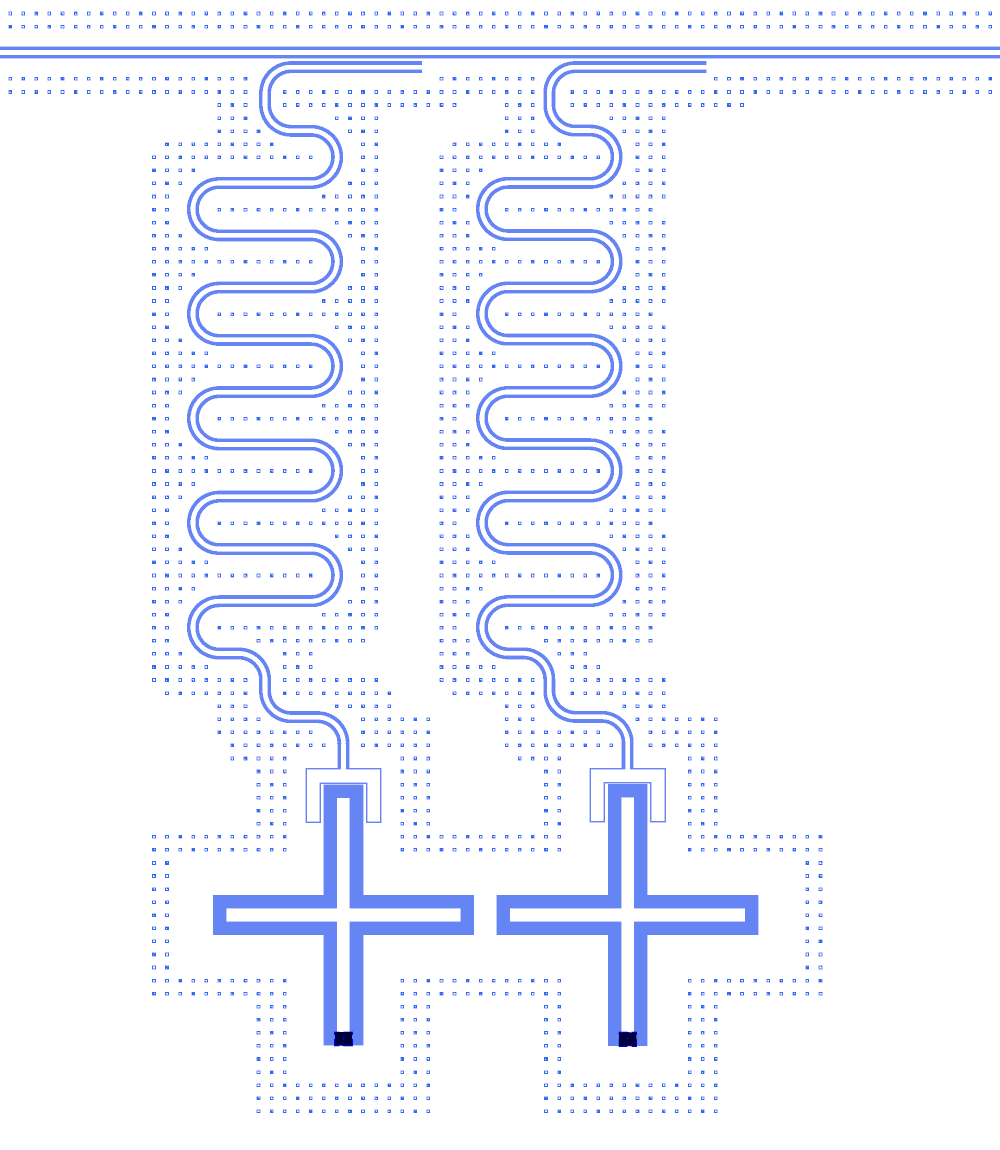

WindowsPath('examples/tutorials/img/t04_rev0.png')

In [9]:
d0 = design(knobs0, "t04_two_qubit", live=LIVE)
rep0 = T.drc(d0)
T.md(T.drc_md(rep0))
T.md(values_md({"LOM rev 0": v0}))
T.snap(d0, "rev0", box=PAIR_BOX, size=(1000, 1150), width=420)

> **Simulation PC (32 GB+ RAM).** The cells below solve the FEM jobs of revision 0 in AEDT: the `PAIR` Q3D, the `ALL` eigenmode + EPR at converged settings (several passes, memory-bound) and the driven S21 (≈ 40 min). On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

## 6 · FEM stage 1: send the jobs, check them (FEM only)

Two sim groups, sized from the FEM-loop lessons (`examples/fem_loop/`):

| group | analyses | box | gives |
|---|---|---|---|
| `PAIR` | `q3d_cmatrix` | both qubits + 200 µm (≈ 1.4 × 1.0 mm); R1, R2 are selected so the build cuts them at the claws: the claws become named nets | C_island, C_g, C_claw of each qubit and the arm-to-arm C_Q1Q2 → J |
| `ALL` | `eigenmode_epr`, `hfss_driven` | both qubits, both readouts and the feedline stretch they hang from + 150 µm (≈ 1.4 × 2.2 mm) | eigenmode: f_q, α (pyEPR), f_r, χ, κ = f/Q, ZZ; driven: two S21 notches → f_r, κ_ext |

- the eigenmode asks for **5 modes above 4.5 GHz**: two qubits, two resonators and a spare slot (a cut feedline can
  bring its own low-Q mode); both feedline ends are terminated in 50 Ω, so a resonator's Q is its external Q;
- the driven run has the **10 µm mesh seed on the gaps** (`mesh_size={"1t1_gap": 10}`) and a fast sweep over both
  notches (24 001 points ≈ 33 kHz apart);
- the Q3D group selects the readouts too: a capacitance build *cuts* the selected routes at the selected qubits
  (each claw gets a 100 µm stub and a port, and becomes a net). A readout that is not selected stays drawn: inside
  the box its claw and line are one floating, port-less conductor (an unlabelled Q3D net). The box still holds only
  the qubits, because the cut readouts are not in the build any more.

`send(d)` saves the design and exports the three jobs (`build/jobs/<design>_<group>_<analysis>/`).

**`FEM_FAST`** (first line of the next cell, default `True`): every job is exported with the library's fast test settings (`sim_tools.export.FAST_SETTINGS`: Q3D 2 % / ≤ 8 passes, eigenmode ΔF 1 % / ≤ 3 passes (memory-bound here), driven ΔS 0.05 / ≤ 6 passes, mesh seeds × 3 (none given: a 40 / 30 µm gap seed for eigenmode / driven), sweeps ≤ 10 001 points), so the whole chain (solve → keep → bring back → feedback → re-solve) runs in minutes. The values are not converged; they move with the design. `False` exports the settings as written for a production run (kept results of a full solve also stand in for a fast re-run of the same design).

In [10]:
# RUN_FEM, AEDT_MODE: the switches at the top (SIM_SUBSET cell)
FEM_FAST = T.fem_fast(FEM_FAST)                   # the switch from the top: fast test settings, or as below
SIM = {
    "q3d_cmatrix": {"percent_error": 0.5},
    "eigenmode_epr": {"n_modes": 5, "min_frequency": 4.5, "max_delta_f": 0.2, "maximum_passes": 14},
    "hfss_driven": {"mesh_size": {"1t1_gap": 10}, "frequency": 7.15, "minimum_passes": 3, "maximum_passes": 10,
                    "sweep_start": 6.7, "sweep_end": 7.5, "sweep_count": 24001, "sweep_type": "fast"},
}
TIMEOUT = {"q3d_cmatrix": 1200, "eigenmode_epr": 2400, "hfss_driven": 3000}      # s


def send(d):
    """Sim groups → save → export one job per (group, analysis). Returns ({analysis: job_dir}, design path)."""
    # SIM_SUBSET → PAIR (Q3D) and ALL (eigenmode, driven): the same selection, two margins; "whole" → "chip"
    pair = T.sim_subset(d, SIM_SUBSET, name="PAIR", margin_um=200, analyses=["q3d_cmatrix"],
                        settings={"q3d_cmatrix": SIM["q3d_cmatrix"]}, show=False)[0]
    full = T.sim_subset(d, SIM_SUBSET, name="ALL", margin_um=150, analyses=["eigenmode_epr", "hfss_driven"],
                        settings={a: SIM[a] for a in ("eigenmode_epr", "hfss_driven")}, show=False)[0]
    path = d.save(T.DESIGNS / f"{d.design.name}.json")
    jobs = {"q3d_cmatrix": C.export_sims(path, [pair], "q3d_cmatrix")[pair]}
    jobs.update({a: C.export_sims(path, [full], a)[full] for a in ("eigenmode_epr", "hfss_driven")})
    return jobs, path


jobs0, DESIGN0 = send(d0)
T.md(C.jobs_md({f"{job[1].group} · {a}": job for a, job in jobs0.items()}))

FEM_FAST: jobs are exported with the fast test settings (q3d_cmatrix percent_error 2, maximum_passes 8, minimum_passes 1; hfss_driven max_delta_s 0.05, maximum_passes 6, minimum_passes 1; eigenmode_epr max_delta_f 1, maximum_passes 3, minimum_passes 1); values are not converged


| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| PAIR · q3d_cmatrix | `build/jobs/t04_two_qubit_PAIR_q3d_cmatrix` | 1 · junction · `Q1.junction`<br>2 · junction · `Q2.junction`<br>3 · waveguide · `Q1.claw_n`<br>4 · waveguide · `Q2.claw_n` | `Q1.island`, `Q2.island`, `Q1.claw_n`, `Q2.claw_n` |
| ALL · eigenmode_epr | `build/jobs/t04_two_qubit_ALL_eigenmode_epr` | 1 · junction · `Q1.junction`<br>2 · junction · `Q2.junction`<br>3 · edge_lumped · `FL`<br>4 · edge_lumped · `FL` | `Q1.island`, `Q2.island`, `FL`, `FL#2` |
| ALL · hfss_driven | `build/jobs/t04_two_qubit_ALL_hfss_driven` | 1 · junction · `Q1.junction`<br>2 · junction · `Q2.junction`<br>3 · edge · `FL`<br>4 · edge · `FL` | `Q1.island`, `Q2.island`, `FL` |

### Solve (`RUN_FEM`)

`RUN_FEM = True` solves the jobs one after the other, each in a **new** non-graphical AEDT 2024 R1 batch process
(`sim_tools.hfss.solve_job`; never an AEDT window you have open; on a timeout only qcc's own process tree is stopped).
A set such as `{"q3d_cmatrix", "eigenmode_epr"}` solves only those analyses — that is one FEM iteration of the loop
(≈ 20–30 min here); add `"hfss_driven"` for the S21 notches. Results are kept in `examples/tutorials/fem/<job>/`;
kept results of the same job are not solved again.

**`AEDT_MODE`** (next to `RUN_FEM`): `"batch"` solves in a new non-graphical AEDT; `"gui"` opens a new AEDT window and leaves it open, so you watch the mesh, the convergence and the fields; `"attach"` runs inside the AEDT window you already have open (or opens one) and leaves the project there. Every mode prints a progress line (step, pass, mesh, ΔF / ΔS / ΔC) every 30 s, so a stuck run is visible; on a timeout only what qcc started is stopped.

In [11]:
# RUN_FEM, AEDT_MODE, RESOLVE: the switches at the top (SIM_SUBSET cell)


def solve(jobs, run_fem, path=None):
    """Solve (or load) one revision's jobs, then the subset check: FEM values only (convergence, raw C-matrix /
    eigenmodes / S21 notches, the FEM-filled capacitances next to the estimates)."""
    from quantcore_circuits.lom.builder import lom_from_design  # pylint: disable=import-outside-toplevel

    keep = {a: T.solve_or_load(job[0], run_fem, timeout=TIMEOUT[a], force=RESOLVE, aedt=AEDT_MODE)
            for a, job in jobs.items()}
    T.subset_check(keep, lom_from_design(path).model if path else None, path)
    return keep


keep0 = solve(jobs0, RUN_FEM, DESIGN0)

t04_two_qubit_PAIR_q3d_cmatrix: the kept results were solved for another revision of this job (design hash or settings differ); they are shown as they are — re-solve with RUN_FEM = True
t04_two_qubit_ALL_eigenmode_epr: the kept results were solved for another revision of this job (design hash or settings differ); they are shown as they are — re-solve with RUN_FEM = True
t04_two_qubit_ALL_hfss_driven: the kept results were solved for another revision of this job (design hash or settings differ); they are shown as they are — re-solve with RUN_FEM = True


| analysis | passes | tets (last) | criterion | last Δ / target | converged | wall time (s) |
|---|---|---|---|---|---|---|
| q3d_cmatrix | 7 | 7788 | Delta % | 1.91 / 2.0 | False | 81.1 |
| eigenmode_epr | 3 | 258703 | Max Delta Freq. % | 3.19 / 1.0 | False | 984.0 |
| hfss_driven | 3 | 243831 | Max Mag. Delta S | 0.0286 / 0.05 | True | 451.5 |

Q3D C-matrix of `t04_two_qubit_PAIR_q3d_cmatrix` (2024.1.0, 81.1 s; Maxwell form, fF):

| net | `Q1.island` | `Q2.island` | `Q1.claw_n` | `Q2.claw_n` |
|---|---|---|---|---|
| `Q1.island` | 100.786 | -0.398 | -2.948 | -0.064 |
| `Q2.island` | -0.398 | 100.814 | -0.064 | -2.947 |
| `Q1.claw_n` | -2.948 | -0.064 | 83.157 | -0.022 |
| `Q2.claw_n` | -0.064 | -2.947 | -0.022 | 83.121 |

Eigenmodes of `t04_two_qubit_ALL_eigenmode_epr` (2024.1.0, 984.0 s):

| mode | f linear (GHz) | Q | p_J | f dressed, pyEPR (GHz) | self-Kerr χ_mm (MHz) |
|---|---|---|---|---|---|
| 1 | 5.1602 | 1.21e+06 | 0.9857 | 5.0108 | -155.3 |
| 2 | 5.4396 | 1.218e+06 | 0.0003 | 5.2935 | -151.2 |
| 3 | 6.8703 | 2.656e+04 | 0.0005 | 6.8702 | -0.0 |
| 4 | 7.1662 | 2.317e+04 | 0.0000 | 7.1661 | -0.0 |
| 5 | 15.5880 | 1.305e+06 | 0.0000 | 15.5880 | 0.0 |

Cross-Kerr (dispersive shift) χ₁₂ = -0.248 MHz (pyEPR, numerical diagonalisation).

Convergence: 3 passes, 258703 tets, last Max Delta Freq. % 3.185 (target 1.0), converged: False.

Driven S-parameters of `t04_two_qubit_ALL_hfss_driven` (2024.1.0, 451.5 s; ports ['FL', 'FL'], 10001 points over [6.7, 7.5] GHz):

| notch | f0 (GHz) | κ_ext/2π (MHz) | Q_c | Q_i | depth | fit residual |
|---|---|---|---|---|---|---|
| S21 | 7.20122 | 0.3778 | 1.906e+04 | 1.06e+06 | 0.891 | 0.00031 |
| S21#2 | 6.70050 | 0.3048 | 2.198e+04 | 1.11e+06 | 0.888 | 0.00011 |

**FEM-filled capacitances of the simulated components** (the other branches keep their estimates):

| branch | nodes | estimate | FEM | from |
|---|---|---|---|---|
| `C_Q1` | Q1 – gnd | 95.85 | 97.38 | `t04_two_qubit_PAIR_q3d_cmatrix` |
| `Cg_Q1_claw_n` | Q1 – Q1.claw_n | 3.17 | 2.948 | `t04_two_qubit_PAIR_q3d_cmatrix` |
| `Cc_Q1_claw_n` | Q1.claw_n – gnd | 76.4 | 65.73 | `t04_two_qubit_PAIR_q3d_cmatrix` |
| `C_Q2` | Q2 – gnd | 96.14 | 97.41 | `t04_two_qubit_PAIR_q3d_cmatrix` |
| `Cg_Q2_claw_n` | Q2 – Q2.claw_n | 3.17 | 2.947 | `t04_two_qubit_PAIR_q3d_cmatrix` |
| `Cc_Q2_claw_n` | Q2.claw_n – gnd | 76.4 | 65.7 | `t04_two_qubit_PAIR_q3d_cmatrix` |
| `C_C_Q1Q2` | Q1 – Q2 | 0.4264 | 0.3981 | `t04_two_qubit_PAIR_q3d_cmatrix` |

**7** branches filled from FEM; **2** kept their estimates (0 outside the subset).
- `t04_two_qubit_PAIR_q3d_cmatrix` (group `PAIR`, q3d_cmatrix): 7 branches; scope Q1, Q2, R1, R2

**Look at these before the whole chip:** if the passes converged (or Δ sits near its target), the capacitances are positive and near their estimates and the qubit mode has p_J ≈ 1, go on and render and simulate the whole chip (stage 2). If not, change the mesh / settings here first: a subset solves in minutes.

> **Simulation PC (32 GB+ RAM).** The cells below fill the whole LOM from the solved jobs and compare estimate with FEM (the LOM calibration against FEM: κ, claws, χ); they need the converged FEM results above. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

## 7 · FEM stage 2: the subset values in the whole LOM — estimate vs FEM

The subset box is the chip minus its pads, so the whole netlist is filled from the stage-1 jobs.

`fem_point(path, keep)` turns the kept jobs into the same five numbers:

- **Q3D** — `fill` replaces the capacitance estimates by the C-matrix values of the same nets (`Q1.island`,
  `Q1.claw_n`, `Q2.island`, `Q2.claw_n`; `C_Q1Q2` is the `Q1.island`–`Q2.island` mutual), then the LOM runs on them:
  f_q, f_r and J on FEM capacitances;
- **eigenmode/EPR** — the full-wave answer: pyEPR's dressed f_q and f_r, α, χ, the qubit–qubit cross-Kerr (static
  ZZ) and κ from each resonator mode's Q (`T.epr_values`: each qubit's mode is the one its own junction participates
  in most).

The FEM value of a target is the eigenmode's where there is one (frequencies), else the LOM on the Q3D values (J).

In [12]:
from quantcore_circuits.lom.builder import lom_from_design


def fem_point(path, keep):
    """FEM values of the design at ``path``: {"q3d": LOM on the C-matrix, "eig": pyEPR, "best": per target}."""
    out = {"q3d": {}, "eig": {}, "best": {}, "filled": None}
    if keep.get("q3d_cmatrix"):
        filled = fill(lom_from_design(path).model, path, keep["q3d_cmatrix"])
        out["q3d"] = dict(simulate(filled, max_modes=4, max_dim=1200).params)
        J = T.exchange_on(lom_from_design(path, ["Q1", "Q2"]).model, path, "Q1", "Q2", job=keep["q3d_cmatrix"],
                          max_modes=2)
        out["q3d"].update(g12_MHz=J["J_MHz"], C_Q1Q2_fF=J["C_ab_fF"])
        out["filled"] = filled
    if keep.get("eigenmode_epr"):
        guess = {r: (out["q3d"] or v0).get(f"{r}.f_GHz", TARGETS[f"{r}.f_GHz"]) for r in ("R1", "R2")}
        out["eig"] = T.epr_values(keep["eigenmode_epr"], {"Q1": "R1", "Q2": "R2"}, guess)
    out["best"] = {**{k: v for k, v in out["q3d"].items() if k in TARGETS},
                   **{k: v for k, v in out["eig"].items() if k in F_KEYS}}
    return out


fem0 = fem_point(DESIGN0, keep0)
# the C-matrix, eigenmodes and S21 notches of rev 0 are in the stage-1 check above
if fem0["best"]:
    extra = ["Q1.alpha_MHz", "Q2.alpha_MHz", "R1.chi_MHz", "R2.chi_MHz", "R1.kappa_MHz", "R2.kappa_MHz"]
    T.md(T.fem_vs_lom_md([(k, v0.get(k), fem0["best"].get(k), "eigenmode + pyEPR" if k in fem0["eig"] else
                           "LOM on the Q3D C-matrix") for k in TARGETS] +
                         [(k, v0.get(k), fem0["eig"].get(k, fem0["q3d"].get(k)), "FEM") for k in extra]
                         + [("Q1-Q2 ZZ (MHz)", None, fem0["eig"].get("Q1-Q2.zz_MHz"), "pyEPR cross-Kerr")]))
else:
    print("No FEM results kept for rev 0: RUN_FEM = True (section 6) solves the jobs; the loop below runs on the "
          "LOM alone until then.")

| quantity | LOM (component estimates) | FEM / LOM on FEM values | Δ | note |
|---|---|---|---|---|
| Q1.f_q_GHz | 5.35 | 5.011 | -6.3 % | eigenmode + pyEPR |
| Q2.f_q_GHz | 5.65 | 5.294 | -6.3 % | eigenmode + pyEPR |
| R1.f_GHz | 6.999 | 6.87 | -1.8 % | eigenmode + pyEPR |
| R2.f_GHz | 7.299 | 7.166 | -1.8 % | eigenmode + pyEPR |
| g12_MHz | 9.999 | 9.192 | -8.1 % | LOM on the Q3D C-matrix |
| Q1.alpha_MHz | -177.7 | -155.3 | +12.6 % | FEM |
| Q2.alpha_MHz | -178 | -151.2 | +15.0 % | FEM |
| R1.chi_MHz | -0.3536 | -0.1642 | +53.6 % | FEM |
| R2.chi_MHz | -0.3849 | -0.1776 | +53.8 % | FEM |
| R1.kappa_MHz | 0.1879 | 0.2525 | +34.4 % | FEM |
| R2.kappa_MHz | 0.2119 | 0.3028 | +42.9 % | FEM |
| Q1-Q2 ZZ (MHz) | – | -0.2485 | – | pyEPR cross-Kerr |

> **Simulation PC (32 GB+ RAM).** The cells below turn FEM − LOM into the next knobs (output space mapping); they are only meaningful on converged FEM results. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

## 8 · Feedback: FEM − LOM → the next knobs (revision 1)

The FEM point says how far the LOM is off *at this geometry*: δ = FEM − LOM for each frequency, and the ratio
J_FEM / J_LOM for the coupling. Output space mapping assumes those differences hold for a small change of the knobs,
so the LOM is asked for shifted targets t′ = t − δ (and J′ = J × J_LOM / J_FEM): the LOM loop then finds knobs
whose **FEM** values land on the real targets. The coupling model is re-anchored on the measured C_Q1Q2 first
(`CC.add`; with two FEM points at different strips it also refits its exponent).

Without FEM results the correction is zero and revision 1 equals revision 0.

In [13]:
def corrected_targets(t, lom, fem):
    """t′: the LOM targets whose FEM values land on ``t`` (additive for frequencies, a ratio for J)."""
    out = dict(t)
    for k in t:
        if fem.get(k) is None or lom.get(k) is None:
            continue
        out[k] = t[k] * lom[k] / fem[k] if k == "g12_MHz" else t[k] - (fem[k] - lom[k])
    return out


if fem0["q3d"].get("C_Q1Q2_fF"):
    CC.add(1 / (2 * GAP + knobs0["strip"]), fem0["q3d"]["C_Q1Q2_fF"])   # anchor the coupling model on the C-matrix
    v0 = lom_values(design(knobs0, "t04_two_qubit"))                    # the LOM with the re-anchored model
t1 = corrected_targets(TARGETS, v0, fem0["best"])
T.md(values_md({"LOM rev 0": v0, "FEM rev 0": fem0["best"], "LOM target t′": t1}))
print("LOM loop on t′:")
knobs1, v1, rows1 = lom_loop(knobs0, t1, "t04_two_qubit_rev1")
T.md(T.before_after_md({k: knobs0[k] for k in knobs1}, knobs1))
d1 = design(knobs1, "t04_two_qubit_rev1", live=LIVE)
print("rev 1 DRC:", "clean" if T.drc(d1).ok else "ERRORS")

| quantity | target | LOM rev 0 | FEM rev 0 | LOM target t′ |
|---|---|---|---|---|
| `Q1.f_q_GHz` | 5.35 | 5.3507 | 5.0108 | 5.6899 |
| `Q2.f_q_GHz` | 5.65 | 5.6507 | 5.2935 | 6.0072 |
| `R1.f_GHz` | 7 | 6.9989 | 6.8702 | 7.1287 |
| `R2.f_GHz` | 7.3 | 7.2987 | 7.1661 | 7.4326 |
| `g12_MHz` | 10 | 9.3394 | 9.1923 | 10.1600 |

LOM loop on t′:


  step 0: Q1.f_q_GHz 5.3507, Q2.f_q_GHz 5.6507, R1.f_GHz 6.9989, R2.f_GHz 7.2987, g12_MHz 9.3394


  step 1: Q1.f_q_GHz 5.6221, Q2.f_q_GHz 5.9323, R1.f_GHz 7.1145, R2.f_GHz 7.4173, g12_MHz 11.8173


  step 2: Q1.f_q_GHz 5.6778, Q2.f_q_GHz 5.9926, R1.f_GHz 7.1272, R2.f_GHz 7.4310, g12_MHz 10.4770


  step 3: Q1.f_q_GHz 5.6877, Q2.f_q_GHz 6.0043, R1.f_GHz 7.1286, R2.f_GHz 7.4324, g12_MHz 10.2161


| quantity | before | after | change |
|---|---|---|---|
| `x1` | 3100 | 3100 | +0 (+0.0 %) |
| `cross1` | 448.95 | 385.97 | -62.98 (-14.0 %) |
| `cross2` | 450.28 | 386.67 | -63.61 (-14.1 %) |
| `lj1` | 7.354 | 7.354 | +0 (+0.0 %) |
| `lj2` | 6.52 | 6.52 | +0 (+0.0 %) |
| `strip` | 44.12 | 50.449 | +6.329 (+14.3 %) |
| `cpl1` | 300 | 300 | +0 (+0.0 %) |
| `cpl2` | 300 | 300 | +0 (+0.0 %) |
| `len1` | 3965.9 | 3885.1 | -80.83 (-2.0 %) |
| `len2` | 3782.6 | 3706 | -76.59 (-2.0 %) |

rev 1 DRC: clean


> **Simulation PC (32 GB+ RAM).** The cells below re-solve revision 1 in AEDT (Q3D, eigenmode + EPR, driven) to check that the FEM lands on target; this is the closed-loop check. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

## 9 · Re-simulate revision 1: does the FEM land on target?

The same jobs for revision 1 (`t04_two_qubit_rev1_*`). The table puts the targets, the rev-0 FEM values, what the
corrected LOM predicts for rev 1 (v_LOM(rev 1) + δ) and the rev-1 FEM values side by side. The loop is closed when
the last column is inside the tolerances; otherwise section 8 runs again on the rev-1 point.

In [14]:
jobs1, DESIGN1 = send(d1)
keep1 = solve(jobs1, RUN_FEM, DESIGN1)
fem1 = fem_point(DESIGN1, keep1)
if fem1["q3d"].get("C_Q1Q2_fF"):                  # a second C-matrix point: the coupling model refits its exponent
    CC.add(1 / (2 * GAP + knobs1["strip"]), fem1["q3d"]["C_Q1Q2_fF"])
    v1 = lom_values(design(knobs1, "t04_two_qubit_rev1"))
pred1 = {k: (v1[k] * fem0["best"][k] / v0[k] if k == "g12_MHz" else v1[k] + fem0["best"][k] - v0[k])
         if fem0["best"].get(k) is not None else v1[k] for k in TARGETS}
T.md(values_md({"FEM rev 0": fem0["best"], "predicted rev 1": pred1, "FEM rev 1": fem1["best"]}))
if fem1["best"]:
    print("rev 1 on target (FEM):", converged({**pred1, **fem1["best"]}, TARGETS))
else:
    print("No FEM results kept for rev 1 yet: with RUN_FEM the jobs above are solved and this table fills in.")

t04_two_qubit_rev1_PAIR_q3d_cmatrix: the kept results were solved for another revision of this job (design hash or settings differ); they are shown as they are — re-solve with RUN_FEM = True
t04_two_qubit_rev1_ALL_eigenmode_epr: the kept results were solved for another revision of this job (design hash or settings differ); they are shown as they are — re-solve with RUN_FEM = True
t04_two_qubit_rev1_ALL_hfss_driven: the kept results were solved for another revision of this job (design hash or settings differ); they are shown as they are — re-solve with RUN_FEM = True


| analysis | passes | tets (last) | criterion | last Δ / target | converged | wall time (s) |
|---|---|---|---|---|---|---|
| q3d_cmatrix | 8 | 10314 | Delta % | 2.34 / 2.0 | False | 40.6 |
| eigenmode_epr | 3 | 249330 | Max Delta Freq. % | 2.77 / 1.0 | False | 994.2 |
| hfss_driven | 4 | 297344 | Max Mag. Delta S | 0.0182 / 0.05 | True | 661.7 |

Q3D C-matrix of `t04_two_qubit_rev1_PAIR_q3d_cmatrix` (2024.1.0, 40.6 s; Maxwell form, fF):

| net | `Q1.island` | `Q2.island` | `Q1.claw_n` | `Q2.claw_n` |
|---|---|---|---|---|
| `Q1.island` | 86.390 | -0.380 | -3.035 | -0.075 |
| `Q2.island` | -0.380 | 86.581 | -0.076 | -3.031 |
| `Q1.claw_n` | -3.035 | -0.076 | 84.792 | -0.029 |
| `Q2.claw_n` | -0.075 | -3.031 | -0.029 | 84.983 |

Eigenmodes of `t04_two_qubit_rev1_ALL_eigenmode_epr` (2024.1.0, 994.2 s):

| mode | f linear (GHz) | Q | p_J | f dressed, pyEPR (GHz) | self-Kerr χ_mm (MHz) |
|---|---|---|---|---|---|
| 1 | 5.5342 | 1.215e+06 | 0.9872 | 5.3613 | -180.3 |
| 2 | 5.8287 | 1.219e+06 | 0.0004 | 5.6599 | -175.2 |
| 3 | 6.9832 | 2.729e+04 | 0.0009 | 6.9831 | -0.0 |
| 4 | 7.3098 | 2.258e+04 | 0.0000 | 7.3096 | -0.0 |
| 5 | 15.5863 | 8.633e+06 | 0.0000 | 15.5863 | 0.0 |

Cross-Kerr (dispersive shift) χ₁₂ = -0.405 MHz (pyEPR, numerical diagonalisation).

Convergence: 3 passes, 249330 tets, last Max Delta Freq. % 2.773 (target 1.0), converged: False.

Driven S-parameters of `t04_two_qubit_rev1_ALL_hfss_driven` (2024.1.0, 661.7 s; ports ['FL', 'FL'], 10001 points over [6.7, 7.5] GHz):

| notch | f0 (GHz) | κ_ext/2π (MHz) | Q_c | Q_i | depth | fit residual |
|---|---|---|---|---|---|---|
| S21 | 6.94641 | 0.3228 | 2.152e+04 | 7.34e+05 | 0.906 | 0.00022 |
| S21#2 | 7.39421 | 0.4168 | 1.774e+04 | 1.1e+06 | 0.873 | 0.00036 |

**FEM-filled capacitances of the simulated components** (the other branches keep their estimates):

| branch | nodes | estimate | FEM | from |
|---|---|---|---|---|
| `C_Q1` | Q1 – gnd | 82.4 | 82.9 | `t04_two_qubit_rev1_PAIR_q3d_cmatrix` |
| `Cg_Q1_claw_n` | Q1 – Q1.claw_n | 3.17 | 3.035 | `t04_two_qubit_rev1_PAIR_q3d_cmatrix` |
| `Cc_Q1_claw_n` | Q1.claw_n – gnd | 76.4 | 67.26 | `t04_two_qubit_rev1_PAIR_q3d_cmatrix` |
| `C_Q2` | Q2 – gnd | 82.55 | 83.09 | `t04_two_qubit_rev1_PAIR_q3d_cmatrix` |
| `Cg_Q2_claw_n` | Q2 – Q2.claw_n | 3.17 | 3.031 | `t04_two_qubit_rev1_PAIR_q3d_cmatrix` |
| `Cc_Q2_claw_n` | Q2.claw_n – gnd | 76.4 | 67.45 | `t04_two_qubit_rev1_PAIR_q3d_cmatrix` |
| `C_C_Q1Q2` | Q1 – Q2 | 0.361 | 0.3799 | `t04_two_qubit_rev1_PAIR_q3d_cmatrix` |

**7** branches filled from FEM; **2** kept their estimates (0 outside the subset).
- `t04_two_qubit_rev1_PAIR_q3d_cmatrix` (group `PAIR`, q3d_cmatrix): 7 branches; scope Q1, Q2, R1, R2

**Look at these before the whole chip:** if the passes converged (or Δ sits near its target), the capacitances are positive and near their estimates and the qubit mode has p_J ≈ 1, go on and render and simulate the whole chip (stage 2). If not, change the mesh / settings here first: a subset solves in minutes.

| quantity | target | FEM rev 0 | predicted rev 1 | FEM rev 1 |
|---|---|---|---|---|
| `Q1.f_q_GHz` | 5.35 | 5.0108 | 5.3473 | 5.3613 |
| `Q2.f_q_GHz` | 5.65 | 5.2935 | 5.6466 | 5.6599 |
| `R1.f_GHz` | 7 | 6.8702 | 6.9998 | 6.9831 |
| `R2.f_GHz` | 7.3 | 7.1661 | 7.2998 | 7.3096 |
| `g12_MHz` | 10 | 9.1923 | 10.5785 | 10.6894 |

rev 1 on target (FEM): False


> **Simulation PC (32 GB+ RAM).** The cells below redesign for a wanted f_q1, rebuild and, with `RUN_FEM`, solve the new revision in AEDT and compare the FEM with what you asked for. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

## 10 · "I want f_q1 = X GHz": redesign → simulate → feedback

Change the input below and run the cell (and the ones after it). The notebook takes the targets with your f_q1,
applies the last FEM correction (from the newest revision that has FEM results), runs the LOM loop to new knobs,
rebuilds (live: redrawn in KLayout), checks the DRC, and — with `RUN_FEM` — solves the new revision and shows how
far the FEM lands from what you asked. Q1's cross length moves first; outside 300–600 µm the junction moves instead,
inside the PDK R_n window (a frequency the window cannot reach shows up as a residual, not as a silent change).

In [15]:
F_Q1_WANTED = 5.45                                # GHz: your qubit-1 frequency (PDK band 4–8 GHz)

wanted = {**TARGETS, "Q1.f_q_GHz": F_Q1_WANTED}
ref_knobs, ref_lom, ref_fem = ((knobs1, v1, fem1["best"]) if fem1["best"] else (knobs0, v0, fem0["best"]))
t_user = corrected_targets(wanted, ref_lom, ref_fem)
print(f"f_q1 → {F_Q1_WANTED} GHz; LOM loop on t′ (FEM correction from {'rev 1' if fem1['best'] else 'rev 0'}"
      f"{'' if ref_fem else ': none yet'}):")
knobs_u, v_u, rows_u = lom_loop(ref_knobs, t_user, "t04_two_qubit_user")
d_u = design(knobs_u, "t04_two_qubit_user", live=LIVE)
rep_u = T.drc(d_u)
T.md(T.drc_md(rep_u))
T.md(T.before_after_md({k: ref_knobs[k] for k in knobs_u}, knobs_u))
jobs_u, DESIGN_U = send(d_u)
keep_u = solve(jobs_u, RUN_FEM, DESIGN_U)
fem_u = fem_point(DESIGN_U, keep_u)
pred_u = {k: (v_u[k] * ref_fem[k] / ref_lom[k] if k == "g12_MHz" else v_u[k] + ref_fem[k] - ref_lom[k])
          if ref_fem.get(k) is not None else v_u[k] for k in wanted}
T.md(values_md({"LOM": v_u, "predicted (LOM + FEM correction)": pred_u, "FEM": fem_u["best"]}, t=wanted))
residual = {k: (fem_u["best"].get(k, pred_u[k]) - wanted[k]) / TOL[k] for k in wanted}
print("residual / tolerance:", {k: round(r, 2) for k, r in residual.items()},
      "→ on target" if all(abs(r) <= 1 for r in residual.values()) else "→ run the feedback again (section 8)")

f_q1 → 5.45 GHz; LOM loop on t′ (FEM correction from rev 1):


  step 0: Q1.f_q_GHz 5.6872, Q2.f_q_GHz 6.0038, R1.f_GHz 7.1286, R2.f_GHz 7.4324, g12_MHz 10.7478


  step 1: Q1.f_q_GHz 5.7579, Q2.f_q_GHz 5.9969, R1.f_GHz 7.1438, R2.f_GHz 7.4239, g12_MHz 10.2999


  step 2: Q1.f_q_GHz 5.7723, Q2.f_q_GHz 5.9948, R1.f_GHz 7.1454, R2.f_GHz 7.4230, g12_MHz 10.1015


**DRC clean** — 0 errors, 0 warnings, 0 PDK design warnings

| severity | rule | count | example |
|---|---|---|---|
| – | – | 0 | – |

| quantity | before | after | change |
|---|---|---|---|
| `x1` | 3100 | 3100 | +0 (+0.0 %) |
| `cross1` | 385.97 | 371.89 | -14.08 (-3.6 %) |
| `cross2` | 386.67 | 388.32 | +1.647 (+0.4 %) |
| `lj1` | 7.354 | 7.354 | +0 (+0.0 %) |
| `lj2` | 6.52 | 6.52 | +0 (+0.0 %) |
| `strip` | 50.449 | 63.991 | +13.54 (+26.8 %) |
| `cpl1` | 300 | 300 | +0 (+0.0 %) |
| `cpl2` | 300 | 300 | +0 (+0.0 %) |
| `len1` | 3885.1 | 3874.9 | -10.17 (-0.3 %) |
| `len2` | 3706 | 3711.4 | +5.364 (+0.1 %) |

... (5 outputs left out)

**FEM-filled capacitances of the simulated components** (the other branches keep their estimates):

| branch | nodes | estimate | FEM | from |
|---|---|---|---|---|
| `C_Q1` | Q1 – gnd | 79.4 | 79.61 | `t04_two_qubit_user_PAIR_q3d_cmatrix` |
| `Cg_Q1_claw_n` | Q1 – Q1.claw_n | 3.17 | 3.04 | `t04_two_qubit_user_PAIR_q3d_cmatrix` |
| `Cc_Q1_claw_n` | Q1.claw_n – gnd | 76.4 | 67.71 | `t04_two_qubit_user_PAIR_q3d_cmatrix` |
| `C_Q2` | Q2 – gnd | 82.91 | 83.6 | `t04_two_qubit_user_PAIR_q3d_cmatrix` |
| `Cg_Q2_claw_n` | Q2 – Q2.claw_n | 3.17 | 3.038 | `t04_two_qubit_user_PAIR_q3d_cmatrix` |
| `Cc_Q2_claw_n` | Q2.claw_n – gnd | 76.4 | 67.64 | `t04_two_qubit_user_PAIR_q3d_cmatrix` |
| `C_C_Q1Q2` | Q1 – Q2 | 0.3469 | 0.3545 | `t04_two_qubit_user_PAIR_q3d_cmatrix` |

**7** branches filled from FEM; **2** kept their estimates (0 outside the subset).
- `t04_two_qubit_user_PAIR_q3d_cmatrix` (group `PAIR`, q3d_cmatrix): 7 branches; scope Q1, Q2, R1, R2

**Look at these before the whole chip:** if the passes converged (or Δ sits near its target), the capacitances are positive and near their estimates and the qubit mode has p_J ≈ 1, go on and render and simulate the whole chip (stage 2). If not, change the mesh / settings here first: a subset solves in minutes.

| quantity | target | LOM | predicted (LOM + FEM correction) | FEM |
|---|---|---|---|---|
| `Q1.f_q_GHz` | 5.45 | 5.7723 | 5.4464 | 5.4546 |
| `Q2.f_q_GHz` | 5.65 | 5.9948 | 5.6509 | 5.6588 |
| `R1.f_GHz` | 7 | 7.1454 | 6.9999 | 6.9907 |
| `R2.f_GHz` | 7.3 | 7.4230 | 7.3001 | 7.2629 |
| `g12_MHz` | 10 | 10.1015 | 10.0466 | 10.2866 |

residual / tolerance: {'Q1.f_q_GHz': 0.92, 'Q2.f_q_GHz': 1.76, 'R1.f_GHz': -1.85, 'R2.f_GHz': -7.42, 'g12_MHz': 0.96} → run the feedback again (section 8)


## 11 · The fab layout

`export_fab` writes only the PDK fab layers (flat): the metal etch with the build's cheese (the PDK band of 5 µm
squares around the 3/0 keep-outs; this design has no cheese of its own), the trilayer junction layers (fingers,
spacer gradient), the 3/0 keep-out derived from the components and routes, the frame and markers, with every corner
rounded (r ∝ the polygon's shortest dimension, ≤ 10 µm; junction fingers stay sharp). `C.pdk_report` sums up the PDK
conformance. The CLI does the same: `qcc mask examples/tutorials/designs/t04_two_qubit_user.json`.

`build/t04_two_qubit_user_fab.oas`: cheese **build** (3083 holes)

| fab layer | polygons |
|---|---|
| `CHIP_BOUNDARY` | 1 |
| `HSQ` | 4 |
| `JJ_BENT` | 2 |
| `JJ_STRAIGHT` | 2 |
| `M1` | 3091 |
| `M3` | 3087 |
| `MARKERS_ALIGN` | 36 |
| `MARKERS_DICING` | 4 |
| `SPACER_1` | 4 |
| `SPACER_2` | 4 |
| `SPACER_3` | 4 |

| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, +16) µm |
| junction types | Quantcore Junction × 2 |
| PDK design warnings | 0 (none) |

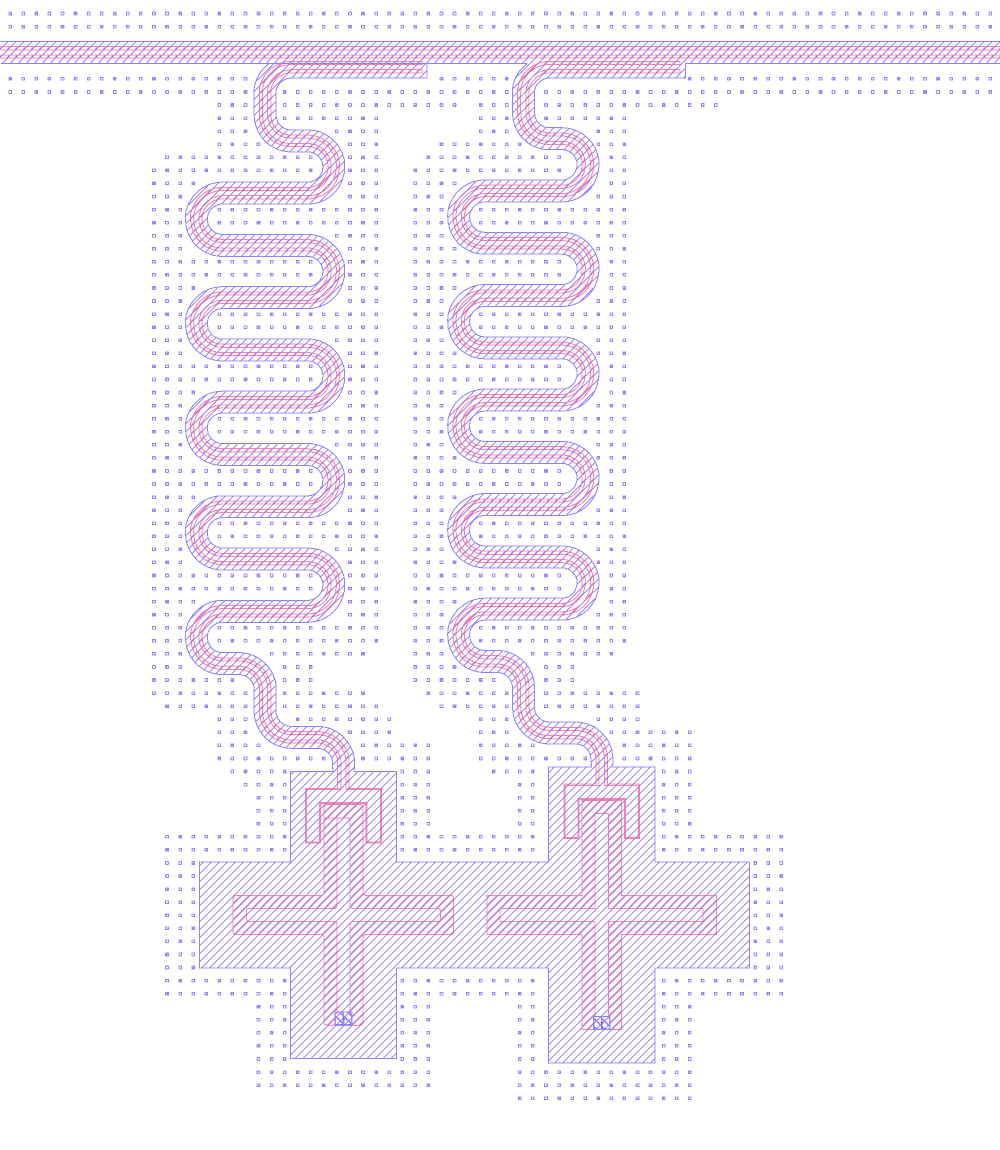

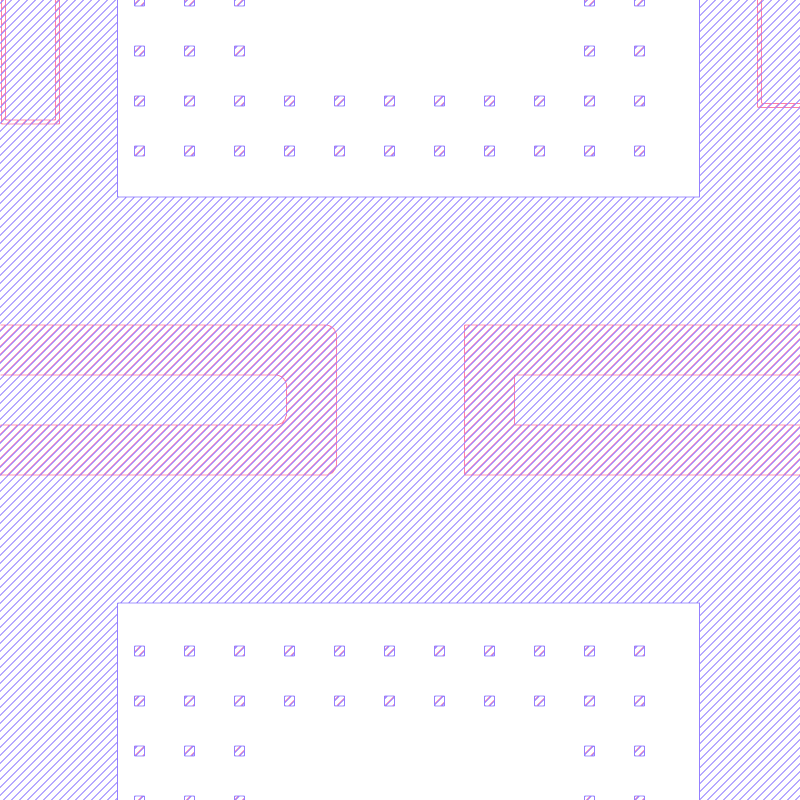

WindowsPath('examples/tutorials/img/t04_fab_tips.png')

In [16]:
import warnings
from quantcore_circuits.layouts.wafers.fab_export import export_fab

report = {}
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    fab = export_fab(T.built(d_u), "build/t04_two_qubit_user_fab.oas", report=report)
T.md(T.fab_report_md(report, fab))
T.md(C.pdk_report(d_u))
x_strip = knobs_u["x1"] + knobs_u["cross1"] / 2 + GAP + knobs_u["strip"] / 2   # centre of the ground strip
TIPS_BOX = (x_strip - 200, Y_Q - 200, x_strip + 200, Y_Q + 200)
T.snap(d_u, "fab_pair", box=PAIR_BOX, size=(1000, 1150), width=420, source=fab)
T.snap(d_u, "fab_tips", box=TIPS_BOX, size=(800, 800), width=320, source=fab)   # strip, cheese, rounding

## 12 · Snapshots

The chip, the two qubits with their facing arms and the ground strip, a junction (trilayer fingers, spacer), and the
layout before and after your f_q1 change. In a live session the Quantcore plugin can also screenshot the KLayout
window (`gui_snapshot`).

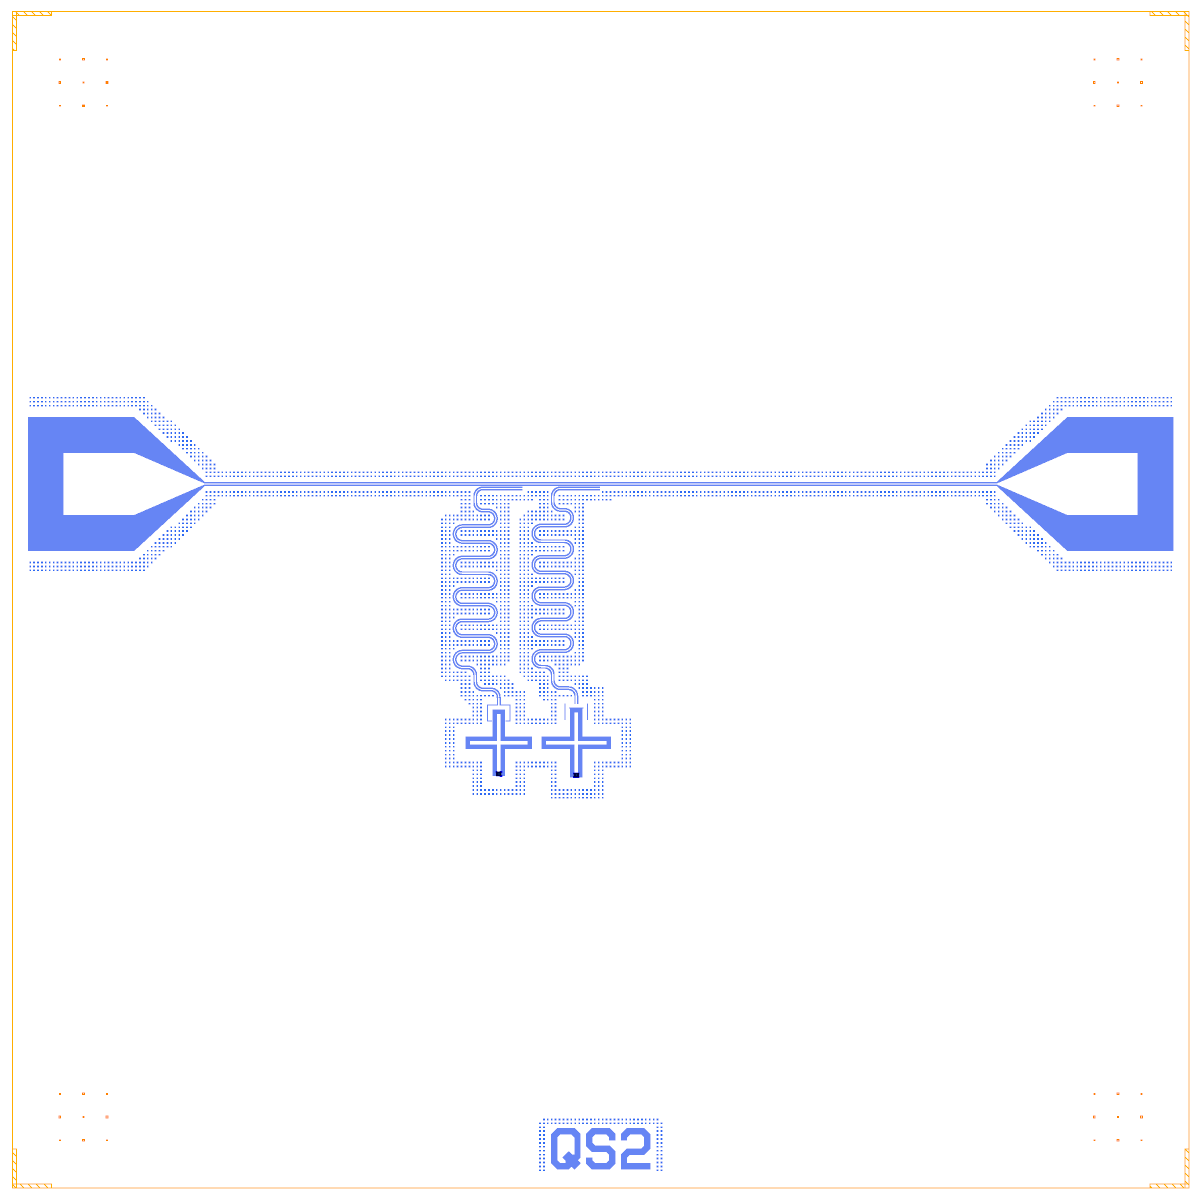

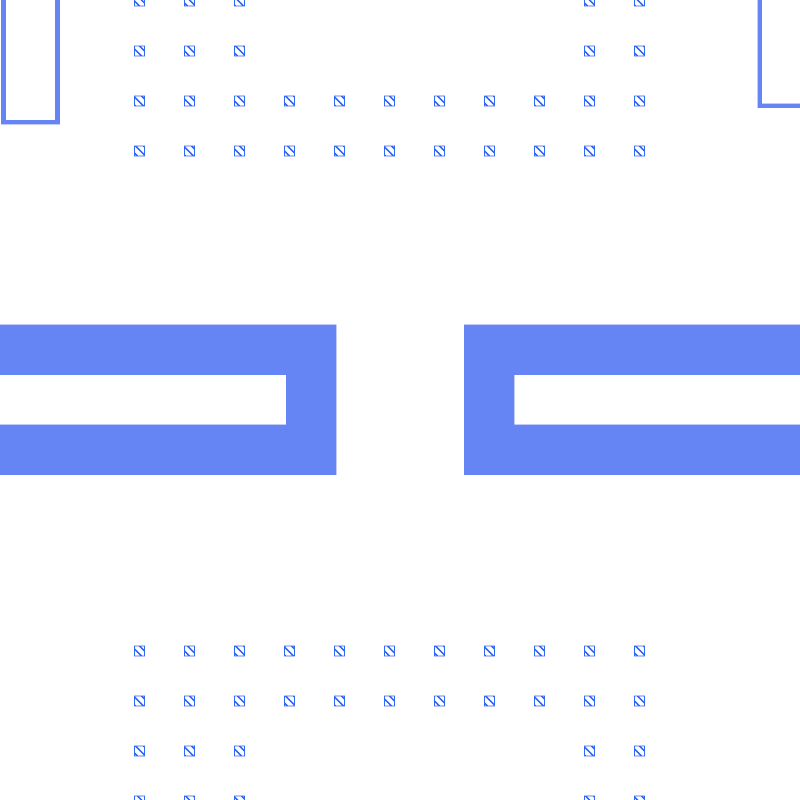

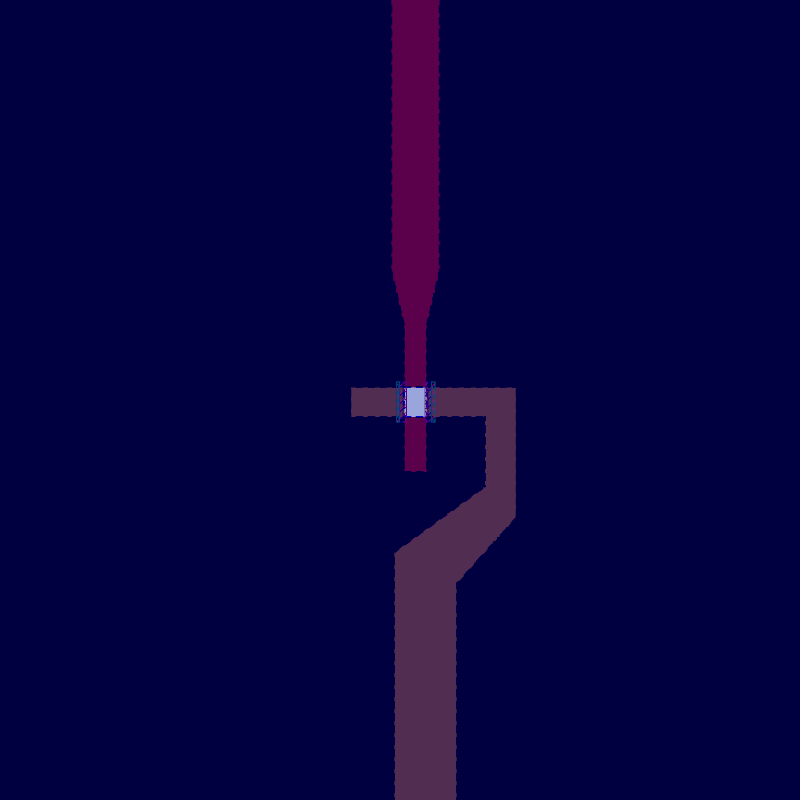

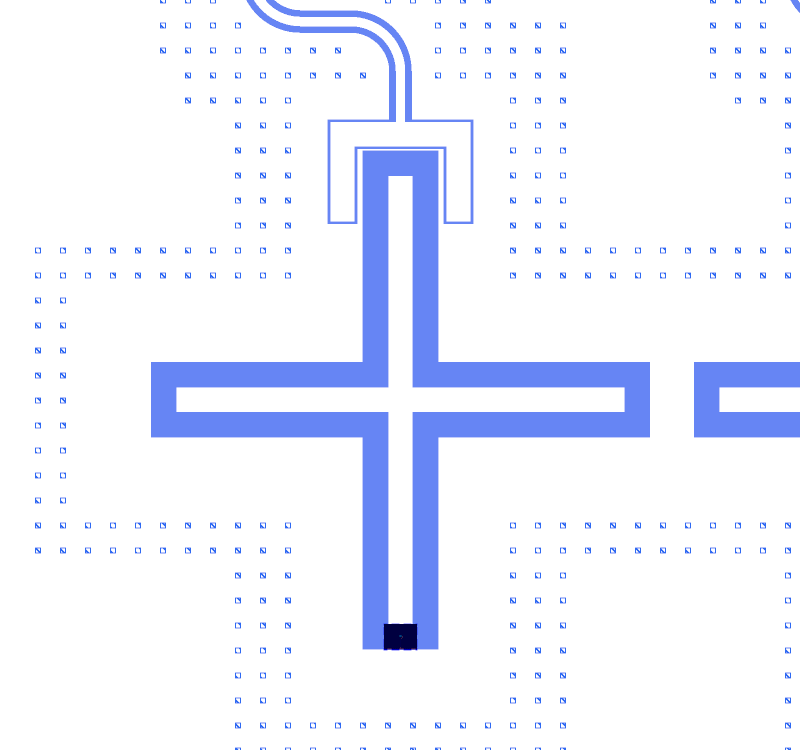

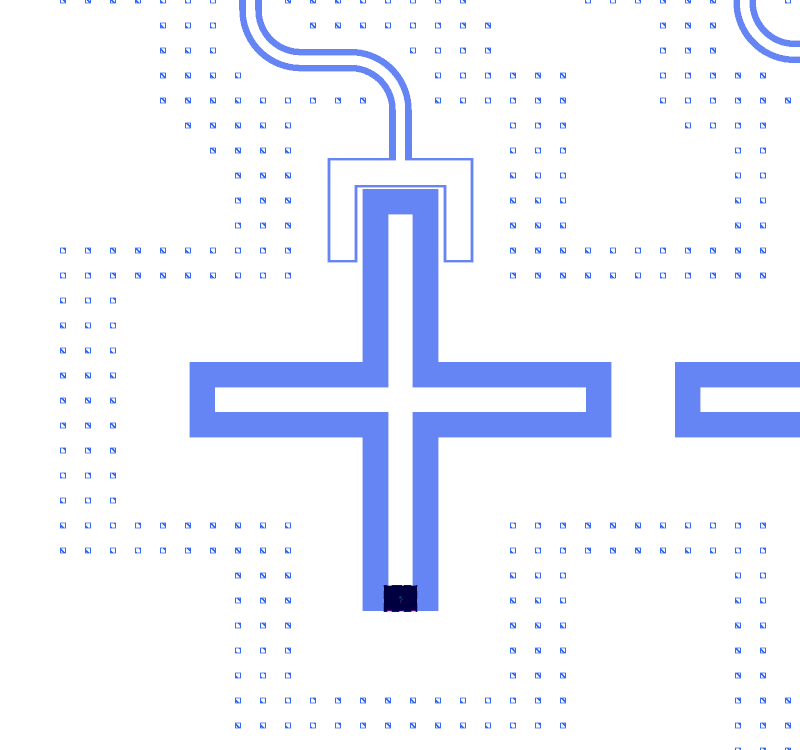

In [17]:
T.snap(d_u, "chip_user", size=(1200, 1200), width=480)
T.snap(d_u, "tips", box=TIPS_BOX, size=(800, 800), width=320)
T.snap(d_u, "junction", box=T.junction_box(d_u, "Q1"), size=(800, 800), width=320)
Q1_BOX = (knobs0["x1"] - 400, Y_Q - 350, knobs0["x1"] + 400, Y_Q + 400)
T.snap(d0, "q1_rev0", box=Q1_BOX, size=(800, 750), width=320)      # before your f_q1 change …
T.snap(d_u, "q1_user", box=Q1_BOX, size=(800, 750), width=320)     # … and after (shorter cross)
if LIVE:
    from quantcore_circuits.live.snapshot import gui_snapshot
    png, how = gui_snapshot(T.IMG / "t04_klayout_window.png", (1200, 900), layout=d_u.out)
    print("KLayout screenshot:", how)

## 13 · Summary

| step | here |
|---|---|
| targets | f_q1 5.35, f_q2 5.65, f_r1 7.00, f_r2 7.30 GHz, g = J₁₂ 10 MHz |
| design | `design(knobs)`: pads at the 100 µm rule, feedline, two Xmons with trilayer junctions and facing arms, two λ/4 hangers; `C_Q1Q2` from the coupling model |
| synthesis | λ/4 lengths, L_J from C_Σ (PDK R_n window), the strip from J |
| DRC / netlist | clean; 2 qubits, 2 readouts, 1 coupling, 2 ports |
| LOM loop | build → LOM → update until the LOM is on target (rev 0) |
| FEM | stage 1 (subset check, FEM only) and stage 2 (fill, LOM vs FEM, feedback) on the same jobs: `PAIR` Q3D (capacitances, C_Q1Q2 → J), `ALL` eigenmode/EPR (f, α, χ, κ, ZZ) and driven S21; kept in `examples/tutorials/fem/` |
| feedback | δ = FEM − LOM → corrected LOM targets → rev 1; re-simulated |
| your target | f_q1 = X: LOM loop with the FEM correction → new revision → DRC → FEM (with `RUN_FEM`) |
| fab | `export_fab`: fab layers, PDK cheese band, rounded corners; `pdk_report` |

**CLI equivalents:** `qcc build examples/tutorials/designs/t04_two_qubit_user.json --show`,
`qcc design drc …`, `qcc circuit export …` / `qcc circuit simulate …`,
`qcc hfss render examples/tutorials/designs/t04_two_qubit.json -g PAIR -a q3d_cmatrix --solve`,
`qcc hfss render … -g ALL -a eigenmode_epr --solve`, `qcc hfss check build/jobs/<job>`, `qcc mask …`.